In [1]:
import pandas as pd
import numpy as np

In [2]:
# %pip install seaborn

In [3]:
# pip install --upgrade pip

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
data = pd.read_csv(r"D:\D DRIVE DOWNLOADS\zr7vgbcyr2-1\metadata.csv")

In [6]:
data.tail()

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
2293,PAT_1708,3156,NaN,NaN,NaN,NaN,73,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1708_3156_175.png,False
2294,PAT_46,880,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,12.0,BCC,True,True,False,True,False,False,PAT_46_880_140.png,True
2295,PAT_1343,1217,NaN,NaN,NaN,NaN,74,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1343_1217_404.png,False
2296,PAT_326,690,False,False,POMERANIA,POMERANIA,58,True,FEMALE,True,...,4.0,BCC,True,False,False,False,False,True,PAT_326_690_823.png,True
2297,PAT_1714,3189,NaN,NaN,NaN,NaN,41,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,True,PAT_1714_3189_989.png,False


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   str    
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   str    
 5   background_mother    1476 non-null   str    
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   str    
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   str    
 15  diameter_1           1494 non-null   float64
 16 

In [8]:
data["patient_id"].nunique()

1373

In [9]:
data["patient_id"].value_counts().head()

patient_id
PAT_645     10
PAT_330     10
PAT_388     10
PAT_53       7
PAT_1414     7
Name: count, dtype: int64

In [10]:
patient_counts = data['patient_id'].value_counts()

print(patient_counts.describe())
print(patient_counts.head(20))

count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: count, dtype: float64
patient_id
PAT_645     10
PAT_330     10
PAT_388     10
PAT_53       7
PAT_1414     7
PAT_747      7
PAT_691      7
PAT_115      7
PAT_270      7
PAT_46       6
PAT_38       6
PAT_380      6
PAT_492      6
PAT_771      6
PAT_63       6
PAT_267      6
PAT_93       6
PAT_1364     6
PAT_108      6
PAT_677      6
Name: count, dtype: int64


In [11]:
data = data.sort_values(by = 'patient_id').reset_index(drop=True)

In [12]:
data

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_10,18,True,False,GERMANY,GERMANY,69,False,MALE,False,...,9.0,SCC,True,UNK,False,UNK,False,True,PAT_10_18_830.png,True
1,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_898.png,True
2,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_595.png,True
3,PAT_1000,31,NaN,NaN,NaN,NaN,65,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1000_31_620.png,False
4,PAT_1006,53,NaN,NaN,NaN,NaN,63,NaN,NaN,NaN,...,NaN,ACK,False,False,False,False,False,False,PAT_1006_53_716.png,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2293,PAT_998,17,NaN,NaN,NaN,NaN,50,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,False,PAT_998_17_641.png,False
2294,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_223.png,False
2295,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_540.png,False
2296,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_583.png,False


In [13]:
data["diagnostic"] = data["diagnostic"].replace({
    "BOD" : "SCC",
})

In [14]:
data["diagnostic"].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [15]:
diagnostic_counts = data["diagnostic"].value_counts()
diagnostic_counts

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [16]:
diagnosis_percentage = (
    data['diagnostic']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(diagnosis_percentage)

diagnostic
BCC    36.77
ACK    31.77
NEV    10.62
SEK    10.23
SCC     8.36
MEL     2.26
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Distribution of diagnostic classes')

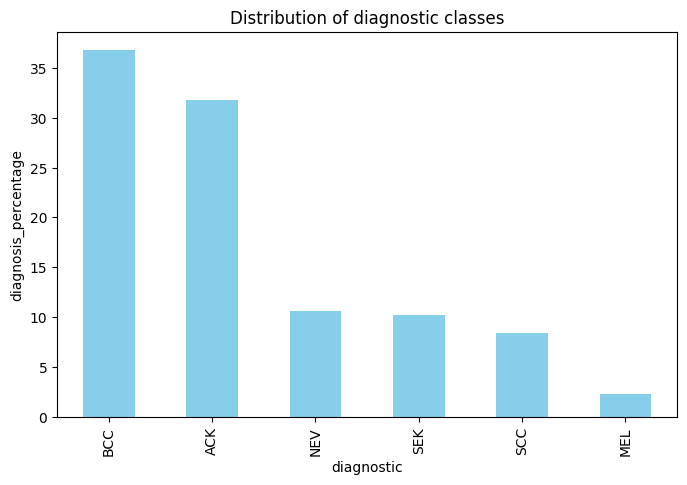

In [17]:
diagnosis_percentage.plot(
    kind = 'bar',
    figsize =(8,5),
    color='skyblue',
)
plt.xlabel("diagnostic")
plt.ylabel("diagnosis_percentage")
plt.title("Distribution of diagnostic classes")

In [18]:
data['diagnostic'].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [19]:
import pandas as pd
from scipy.stats import chi2_contingency

def chi_square_test(data, feature, target='diagnostic'):
    contingency = pd.crosstab(data[feature], data[target])
    chi2, p, dof, expected = chi2_contingency(contingency)
    
    # Cramér's V for effect size
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    cramers_v = (chi2 / (n * min_dim)) ** 0.5
    
    return {
        'feature': feature,
        'chi2': round(chi2, 2),
        'p_value': p,
        'cramers_v': round(cramers_v, 3),
        'significant': p < 0.05
    }

# list all your categorical features here
categorical_features = ['itch', 'grew', 'hurt', 'changed', 'elevation', 'bleed',
                         'cancer_history', 'skin_cancer_history', 'smoke', 'drink',
                         'background_father', 'background_mother', 'gender',
                         'region', 'pesticide', 'biopsed']  # keep biopsed in for now just to see, but don't use it as an input feature later

results = []
for feat in categorical_features:
    if feat in data.columns:
        results.append(chi_square_test(data, feat, target='diagnostic'))

results_df = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
print(results_df)

                feature     chi2        p_value  cramers_v  significant
15              biopsed  1499.94   0.000000e+00      0.808         True
1                  grew   855.71  2.160752e-177      0.431         True
0                  itch   654.96  2.905929e-134      0.378         True
3               changed   653.57  5.783800e-134      0.377         True
4             elevation   651.17  1.885568e-133      0.376         True
5                 bleed   581.74  1.435794e-118      0.356         True
13               region   987.84  5.093887e-165      0.293         True
2                  hurt   374.50   2.495937e-74      0.285         True
14            pesticide    31.44   7.663615e-06      0.145         True
8                 smoke    29.43   1.910254e-05      0.140         True
10    background_father   104.46   3.331274e-04      0.119         True
11    background_mother    75.36   1.171644e-02      0.101         True
12               gender    12.22   3.194504e-02      0.090      

In [20]:
data['cancer_binary'] = data['diagnostic'].map({
    'BCC':'Cancer','SCC':'Cancer','MEL':'Cancer',
    'ACK':'Non-cancer','NEV':'Non-cancer','SEK':'Non-cancer'
})

for feat in ['cancer_history','skin_cancer_history']:
    ct = pd.crosstab(data[feat], data['cancer_binary'])
    chi2, p, dof, exp = chi2_contingency(ct)
    print(feat, 'p =', p)

cancer_history p = 0.8772859466160792
skin_cancer_history p = 0.1255592993129681


In [21]:
data['cancer_history'].value_counts(normalize=True)


cancer_history
True     0.521419
False    0.478581
Name: proportion, dtype: float64

In [22]:
from sklearn.model_selection import GroupShuffleSplit
#we  use  this to make sure the  patient data is not split across train and test sets. This is important because we don't want data from the same patient in both sets, which could lead to data leakage and overfitting

In [23]:
groups = data['patient_id']

In [24]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

In [25]:
train_idx, test_idx = next(gss.split(data, groups=groups))

In [26]:
train_idx[:10]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [27]:
len(train_idx), len(test_idx)

(1837, 461)

In [28]:
train_patients = set(data.loc[train_idx, 'patient_id'])
test_patients = set(data.loc[test_idx, 'patient_id']) #set removes overlapping patient ids that are in multiple rowsjsut to check if overlapping so once patient id is enough
train_patients & test_patients #and checks no  id is overlapped in train and test

set()

In [29]:
print(data.loc[train_idx, 'diagnostic'].value_counts(normalize=True))
print(data.loc[test_idx, 'diagnostic'].value_counts(normalize=True))

diagnostic
BCC    0.365269
ACK    0.328253
NEV    0.106151
SEK    0.097986
SCC    0.077844
MEL    0.024496
Name: proportion, dtype: float64
diagnostic
BCC    0.377440
ACK    0.275488
SEK    0.119306
NEV    0.106291
SCC    0.106291
MEL    0.015184
Name: proportion, dtype: float64


In [30]:
train_df = data.loc[train_idx].reset_index(drop=True)
test_df = data.loc[test_idx].reset_index(drop=True)

In [31]:
train_df.isna().sum()


patient_id               0
lesion_id                0
smoke                  641
drink                  641
background_father      653
background_mother      654
age                      0
pesticide              641
gender                 641
skin_cancer_history    641
cancer_history         641
has_piped_water        641
has_sewage_system      641
fitspatrick            641
region                   0
diameter_1             641
diameter_2             641
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
cancer_binary            0
dtype: int64

In [33]:
train_df['biopsed'].value_counts()

biopsed
True     1071
False     766
Name: count, dtype: int64